# Cell-type annotation with scPISCES: MERFISH

Explore saved scPISCES annotations of 6,602 mouse spinal-cord MERFISH
cells, then map selected populations back to the tissue. The figures
below are already rendered. Rerunning this example needs only the bundled data.

## 1. Load the example

Each row contains a curated annotation, a predicted identity and coordinates. Spatial coordinates are used for visualization only.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import configure_plots, save_figure, clean_map, pretty, expression_cmap

configure_plots()
DATA = ROOT / "tutorials/data"
OUTPUT = ROOT / "tutorials/outputs"

In [2]:
cells = pd.read_csv(DATA / "merfish_cells.csv.gz", dtype={"cell_id": str})
assert cells.cell_id.is_unique
display(cells.head())
print(f"{len(cells):,} cells | {cells.annotated_cell_type.nunique()} annotated populations")

,cell_id,annotated_cell_type,predicted_cell_type,spatial_x,spatial_y,UMAP1,UMAP2
0,2787445900215100190,astrocyte-2,astrocyte-2,8607.01041,1571.38068,5.699472,-0.384619
1,2787445900215100193,astrocyte-2,astrocyte-2,8573.00979,1573.94456,5.689179,-0.521454
2,2787445900215100194,astrocyte-2,astrocyte-2,8553.93255,1575.78204,6.717373,-0.880620
3,2787445900215100198,astrocyte-2,astrocyte-2,8463.82026,1577.91724,5.707376,1.297723
4,2787445900216100058,astrocyte-2,astrocyte-2,8639.53261,1571.71125,5.940280,-0.474895


6,602 cells | 59 annotated populations


## 2. Inspect the annotations

Compute summary metrics from the saved labels. Accuracy is the fraction of matching labels; macro-F1 gives equal weight to each population.

In [3]:
import json
from sklearn.metrics import accuracy_score, f1_score, adjusted_rand_score

truth = cells.annotated_cell_type
predicted = cells.predicted_cell_type
metrics = pd.Series({
    "Accuracy": accuracy_score(truth, predicted),
    "Macro-F1": f1_score(truth, predicted, average="macro"),
    "Weighted F1": f1_score(truth, predicted, average="weighted"),
    "ARI": adjusted_rand_score(truth, predicted),
}, name="scPISCES")
expected = json.loads((DATA / "merfish_expected_metrics.json").read_text())
assert np.isclose(metrics["Accuracy"], expected["accuracy"])
assert np.isclose(metrics["Macro-F1"], expected["macro_f1"])
display(metrics.to_frame().round(3))

,scPISCES
Accuracy,0.885
Macro-F1,0.814
Weighted F1,0.886
ARI,0.822


## 3. Visualize the model representation

The same model-embedding UMAP is colored by curated and predicted identities. Six selected populations are highlighted; all other cells remain gray.

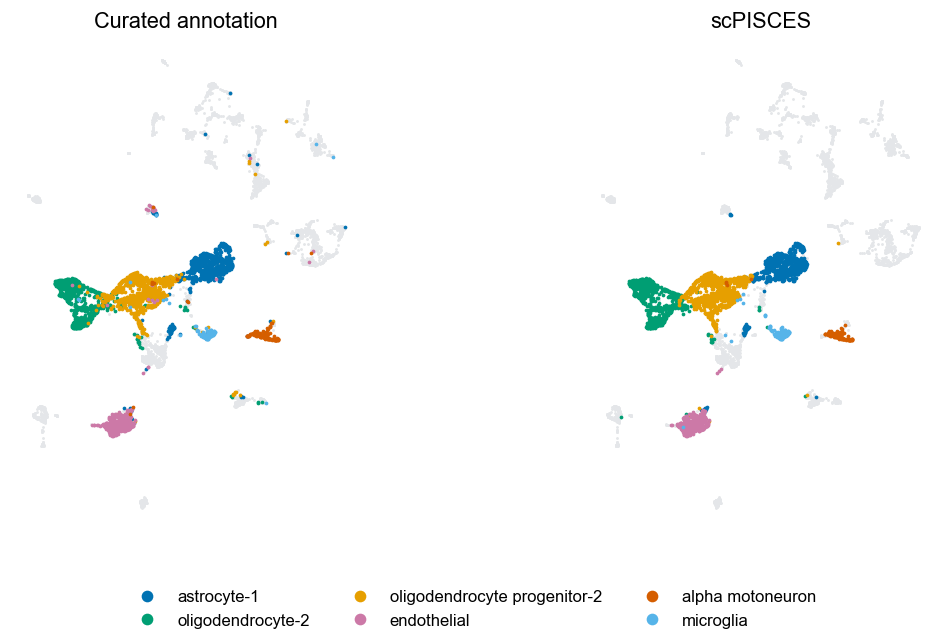

In [4]:
from matplotlib.lines import Line2D

palette = {
    "astrocyte-1": "#0072B2",
    "oligodendrocyte-2": "#009E73",
    "oligodendrocyte progenitor-2": "#E69F00",
    "endothelial": "#CC79A7",
    "alpha motoneuron": "#D55E00",
    "microglia": "#56B4E9",
}
fig, axes = plt.subplots(1, 2, figsize=(12, 5.7))
for ax, column, title in zip(axes,
        ["annotated_cell_type", "predicted_cell_type"],
        ["Curated annotation", "scPISCES"]):
    ax.scatter(cells.UMAP1, cells.UMAP2, s=3, c="#e4e6e9", linewidths=0)
    for population, color in palette.items():
        subset = cells.loc[cells[column].eq(population)]
        ax.scatter(subset.UMAP1, subset.UMAP2, s=5, c=color, linewidths=0)
    ax.set_title(title)
    clean_map(ax)
handles = [Line2D([], [], marker="o", linestyle="", color=c, label=n, markersize=6)
           for n, c in palette.items()]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10)
fig.subplots_adjust(bottom=0.16, wspace=0.06)
save_figure(fig, OUTPUT, "merfish_annotation_umap")
plt.show()

## 4. Recover spatial subtype patterns

Change `populations` to inspect other identities. Recall is the fraction of curated cells of that type assigned the same label.

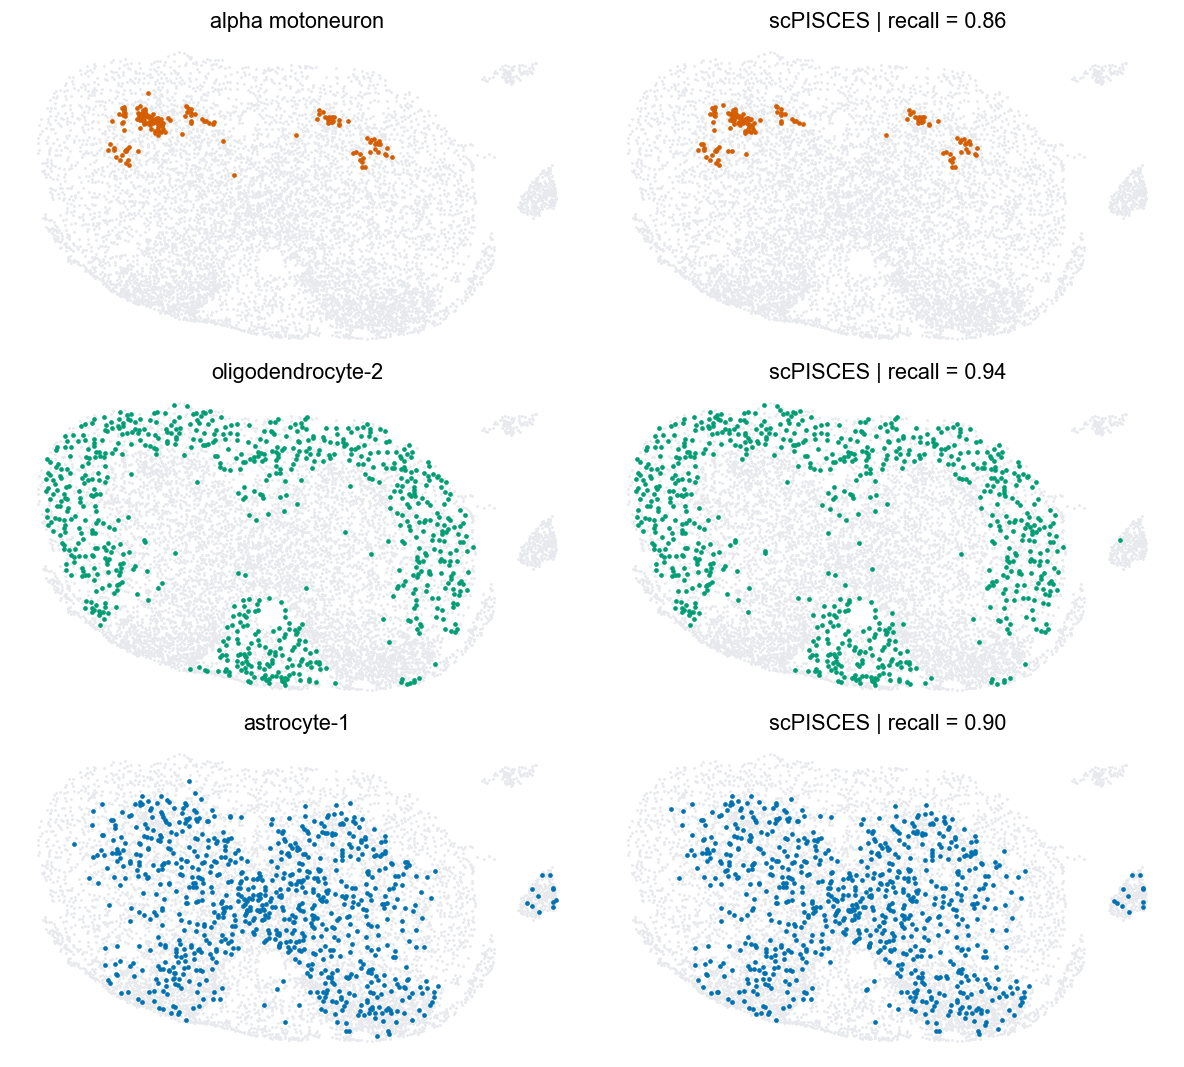

In [5]:
populations = ["alpha motoneuron", "oligodendrocyte-2", "astrocyte-1"]
fig, axes = plt.subplots(len(populations), 2, figsize=(10, 9))
for row, population in enumerate(populations):
    mask = truth.eq(population)
    recall = predicted[mask].eq(population).mean()
    for col, label in enumerate(["annotated_cell_type", "predicted_cell_type"]):
        ax = axes[row, col]
        subset = cells.loc[cells[label].eq(population)]
        ax.scatter(cells.spatial_x, cells.spatial_y, s=3, c="#e7e9ec", linewidths=0)
        ax.scatter(subset.spatial_x, subset.spatial_y, s=8,
                   c=palette.get(population, "#0072B2"), linewidths=0)
        ax.set_title(population if col == 0 else f"scPISCES | recall = {recall:.2f}")
        clean_map(ax)
fig.tight_layout(h_pad=1.0)
save_figure(fig, OUTPUT, "merfish_spatial_subtypes")
plt.show()

## 5. Annotate a new query

After installing scPISCES, use the helper below with a compatible
fine-tuned checkpoint and its vocabulary. The query expression matrix
should use the preprocessing expected by that model. This optional
step needs your model assets; the bundled example above is self-contained.

In [6]:
import subprocess

def annotate_query(query_h5ad, checkpoint, vocabulary, output_csv, device="cpu"):
    command = [
        sys.executable, str(ROOT / "scripts/predict_scpisces.py"),
        "--checkpoint", str(checkpoint), "--h5ad", str(query_h5ad),
        "--vocab", str(vocabulary), "--output", str(output_csv),
        "--head", "sparse", "--device", device,
    ]
    if device == "cpu":
        command.append("--no-amp")
    subprocess.run(command, check=True, cwd=ROOT)
    return pd.read_csv(output_csv, dtype={"cell_id": str})

# Uncomment after supplying your model assets:
# predictions = annotate_query(
#     ROOT / "data/query.h5ad", ROOT / "assets/merfish/best.pth",
#     ROOT / "assets/merfish/vocab.json", OUTPUT / "query_predictions.csv",
# )

The result contains `cell_id`, `predicted_cell_type` and `confidence`.
Set `device="cuda"` to use a GPU. Saved figures above reproduce the
archived study predictions; a different model can give different results.